# Fixed 10+1 features: rate/spread discount-factor changes only

Repeat the five-model comparison for the **same five macro/market features, five technical features and mandatory S&P log return** as notebook 04, using the transformations from Anton Vorobets's **chapter3_1.ipynb, Section 3.1**. The equations and transformation code follow the [Fortitudo/pcrm-book example](https://github.com/fortitudo-tech/pcrm-book); its attribution and license notice are retained below.

For a rate or spread quoted in percent, construct a constant-reference-maturity discount proxy and its log change:

$$D_t(\tau)=\exp(-\tau y_t/100),\qquad u_t=\log D_t-\log D_{t-1}=-\tau\Delta y_t/100.$$

Apply the new change transformation **only to breakeven inflation, the real yield, the Treasury slope and the Baa spread**. VIX and all five technical inputs keep exactly notebook 04's treatment: natural log levels for VIX/realized volatility, with no time differences, and the existing momentum, drawdown, RSI and relative-momentum definitions. The S&P input stays its saved daily log return. This is a **stationary-transformation candidate**, not a claim that all eleven series are now stationary.

A matched-date level control repeats the **entire 85-candidate search**, so changing the observation calendar does not explain the difference. The final section runs K-means K=2 EP/FFR and compares it with the original and matched-date notebook-04 level specifications.


In [1]:
from pathlib import Path
from time import perf_counter
from itertools import combinations
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from scipy.spatial.distance import pdist, squareform
from kmedoids import KMedoids

sns.set_theme(style="whitegrid", palette="colorblind", font_scale=0.9)
output_dir = Path("data/stationary_feature_clustering")
output_dir.mkdir(parents=True, exist_ok=True)


## Load the original calendar before taking differences

Use the saved 50-feature panel **with missing dates retained**, then select the declared eleven inputs. Differences are calculated on the original equity trading calendar before complete-case filtering. No filling or changes across skipped equity dates.


In [2]:
specification = pd.read_csv("paper/tables/primary_feature_specification.csv")
features = pd.read_csv("data/random_features/feature_pool_50.csv", index_col="date", parse_dates=["date"])
outcomes = pd.read_csv("data/random_features/sp500_outcomes.csv", index_col="date", parse_dates=["date"])
original = features.join(outcomes[["sp500_log_return"]])[specification["feature"]].copy()
old_dates = pd.read_csv("data/fixed_feature_clustering/ep_selected_assignments.csv",
                        index_col="date", parse_dates=["date"]).index
original.head()


Out[2]: 
            breakeven_10y  ...  sp500_log_return
date                       ...                  
2011-10-05           1.80  ...          0.017708
2011-10-06           1.88  ...          0.018138
2011-10-07           1.94  ...         -0.008197
2011-10-10            NaN  ...          0.033556
2011-10-11           1.95  ...          0.000544

[5 rows x 11 columns]


## Discount proxies, not traded zero-coupon bond returns

Our inputs are not a bootstrapped zero-coupon curve. [DFII10](https://fred.stlouisfed.org/series/DFII10) is a quoted constant-maturity real yield; [T10YIE](https://fred.stlouisfed.org/series/T10YIE), [T10Y2Y](https://fred.stlouisfed.org/series/T10Y2Y) and [BAA10Y](https://fred.stlouisfed.org/series/BAA10Y) are rate/spread descriptors. Applying the chapter's formula therefore produces **discount-factor-style proxies**, without coupon, carry or roll-down P&L.

Use a ten-year reference for the ten-year real-yield/breakeven descriptors and a one-year reference index for the two spread descriptors. The spread references are normalization conventions, not estimates of instrument maturity or duration. With fixed positive maturity and columnwise StandardScaler, the rate transform is exactly a sign-reversed standardized first difference: **maturity does not change the fitted Euclidean geometry**. Negative yields/spreads are allowed because the exponential proxy stays positive.


In [3]:
rate_maturities = pd.Series({"breakeven_10y": 10.0, "real_yield_10y": 10.0,
                             "slope_10y_2y": 1.0, "baa_10y_spread": 1.0})
rate_columns = rate_maturities.index.tolist()
vol_columns = ["vix", "sp500_realized_vol_21d"]

# Discount-factor and log-change construction adapted from Vorobets, chapter3_1.
discount_factors = np.exp(-original[rate_columns] / 100 * rate_maturities)
transformed = original.copy()
transformed[rate_columns] = np.log(discount_factors).diff()
transformed[vol_columns] = np.log(original[vol_columns])  # Same log levels as 04; no differences.

transformed_names = {column: column + "_zc_log_change" for column in rate_columns}
transformed = transformed.rename(columns=transformed_names)
df_transformed = transformed.reindex(old_dates).dropna().copy()
df = original.loc[df_transformed.index].copy()
level_inputs = df.copy()
level_inputs[vol_columns] = np.log(level_inputs[vol_columns])

print(f"{len(df):,} matched dates: {df.index.min().date()} to {df.index.max().date()}")
print(f"{len(old_dates) - len(df)} notebook-04 dates excluded because a daily change needs both observations.")
display(df_transformed.head())

transformation_table = specification.copy()
transformation_table["model_column"] = transformation_table["feature"].replace(transformed_names)
transformation_table["new_transformation"] = "Keep saved descriptor"
transformation_table.loc[transformation_table["feature"].isin(rate_columns), "new_transformation"] = "Log change of discount proxy"
transformation_table.loc[transformation_table["feature"].isin(vol_columns), "new_transformation"] = "Keep log level from 04; no differencing"
transformation_table.loc[transformation_table["feature"].eq("sp500_log_return"), "new_transformation"] = "Keep daily log return"
transformation_table["reference_years"] = transformation_table["feature"].map(rate_maturities)
transformation_table[["block", "feature", "model_column", "new_transformation", "reference_years"]]


3,604 matched dates: 2011-10-06 to 2026-10-02
26 notebook-04 dates excluded because a daily change needs both observations.
Out[3]: 
            block  ... reference_years
0    macro_market  ...            10.0
1    macro_market  ...            10.0
2    macro_market  ...             1.0
3    macro_market  ...             1.0
4    macro_market  ...             NaN
5       technical  ...             NaN
6       technical  ...             NaN
7       technical  ...             NaN
8       technical  ...             NaN
9       technical  ...             NaN
10  return_anchor  ...             NaN

[11 rows x 5 columns]


,breakeven_10y_zc_log_change,real_yield_10y_zc_log_change,slope_10y_2y_zc_log_change,baa_10y_spread_zc_log_change,vix,sp500_momentum_63d,sp500_drawdown_252d,sp500_realized_vol_21d,sp500_rsi_14d,small_large_momentum_21d,sp500_log_return
date,,,,,,,,,,,
2011-10-06,-0.008,-0.001,-0.0005,0.0002,3.590991,-0.142806,-0.145672,3.385934,49.861520,-0.022975,0.018138
2011-10-07,-0.006,-0.003,-0.0008,0.0002,3.589059,-0.132747,-0.152646,3.383162,48.131934,-0.032914,-0.008197
2011-10-12,-0.003,-0.003,-0.0009,-0.0001,3.442339,-0.080819,-0.114666,3.406812,57.168540,-0.017325,0.009747
2011-10-13,0.006,-0.001,0.0005,0.0004,3.424263,-0.089336,-0.117299,3.397622,56.348993,-0.020213,-0.002978
2011-10-14,-0.006,-0.001,-0.0008,0.0003,3.340739,-0.063942,-0.101957,3.398044,59.951899,-0.014423,0.017231


## Scale and retain all informative PCs

The standard transformation fit and level control each fit their own scaler on the **same dates** and retain all informative, unwhitened PCs. Their native silhouettes refer to different geometries and cannot alone establish that one representation is better. Later we also score both partitions in shared reference spaces.


In [4]:
scaled_df = pd.DataFrame(StandardScaler().fit_transform(df_transformed),
                         index=df.index, columns=df_transformed.columns)
level_scaled_df = pd.DataFrame(StandardScaler().fit_transform(level_inputs),
                               index=df.index, columns=level_inputs.columns)
pca = PCA(n_components=np.linalg.matrix_rank(scaled_df), svd_solver="full")
data_pca = pd.DataFrame(pca.fit_transform(scaled_df), index=df.index,
                        columns=[f"PC{i+1}" for i in range(pca.n_components_)])
level_pca = PCA(n_components=np.linalg.matrix_rank(level_scaled_df), svd_solver="full")
representations = {"Standard": data_pca.to_numpy(), "Levels": level_pca.fit_transform(level_scaled_df)}
evaluation_values = {"Standard": scaled_df.to_numpy(), "Levels": level_scaled_df.to_numpy()}
evaluation_distances = {name: squareform(pdist(values)) for name, values in evaluation_values.items()}
fit_distances = evaluation_distances.copy()
pca_variance = pd.DataFrame({"Explained variance": pca.explained_variance_ratio_,
                            "Cumulative variance": np.cumsum(pca.explained_variance_ratio_)}, index=data_pca.columns)
rate_difference_scaled = StandardScaler().fit_transform(original[rate_columns].diff().loc[df.index])
rate_proxy_scaled = scaled_df[[transformed_names[column] for column in rate_columns]].to_numpy()
equivalence_error = np.max(np.abs(rate_proxy_scaled + rate_difference_scaled))
print(f"11 inputs, {data_pca.shape[1]} informative PCs. Standardized rate-change equivalence error: {equivalence_error:.2e}")
display(pca_variance.round(4))


11 inputs, 11 informative PCs. Standardized rate-change equivalence error: 5.89e-13


,Explained variance,Cumulative variance
PC1,0.3236,0.3236
PC2,0.1446,0.4682
PC3,0.1177,0.5860
PC4,0.1024,0.6883
PC5,0.0877,0.7761
PC6,0.0662,0.8422
PC7,0.0532,0.8954
PC8,0.0401,0.9355
PC9,0.0289,0.9643
PC10,0.0210,0.9853


## Persistence check

Compare lag-one autocorrelations on the same retained dates. Gaps caused by missing source observations remain gaps; these correlations use adjacent retained rows. A reduced autocorrelation is a descriptive check, **not an ADF/KPSS stationarity test**. The seven other inputs, including VIX and all technicals, retain their notebook-04 treatment and can remain persistent. The before/after table compares actual model inputs, so unchanged inputs have identical correlations.


,"04 input, matched dates",New model input
breakeven_10y,0.996,0.066
real_yield_10y,0.999,0.047
slope_10y_2y,0.999,-0.045
baa_10y_spread,0.999,0.134
vix,0.967,0.967
sp500_momentum_63d,0.971,0.971
sp500_drawdown_252d,0.983,0.983
sp500_realized_vol_21d,0.987,0.987
sp500_rsi_14d,0.907,0.907
small_large_momentum_21d,0.946,0.946


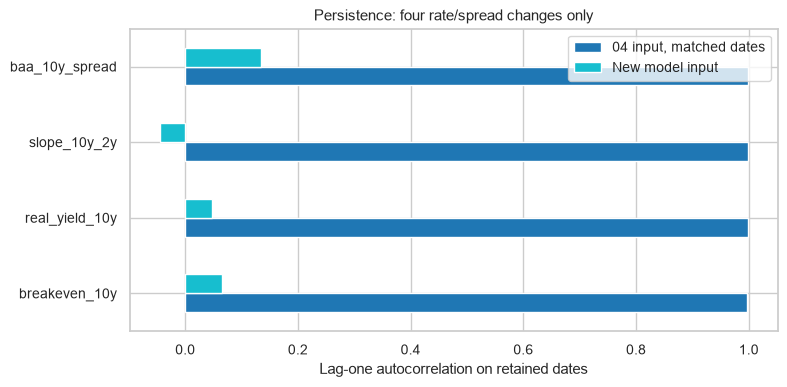

In [5]:
persistence = pd.DataFrame({"04 input, matched dates": level_inputs.apply(lambda s: s.autocorr()).to_numpy(),
                            "New model input": df_transformed.apply(lambda s: s.autocorr()).to_numpy()},
                           index=df.columns)
display(persistence.round(3))
persistence.loc[rate_columns].plot.barh(figsize=(8, 4), colormap="tab10")
plt.xlabel("Lag-one autocorrelation on retained dates")
plt.title("Persistence: four rate/spread changes only")
plt.tight_layout()
plt.savefig(output_dir / "persistence_comparison.png", dpi=160)
plt.show()


## Same tuning rules as 04

For each representation independently, run the full **85-candidate** grid: K-means K=2–8 with 20 starts; K-medoids K=2–8 and seeds 1/7; hierarchical K=2–8 with Ward/average/complete; GMM K=2–8 with full/tied/diagonal/spherical covariance; DBSCAN min_samples=5/10/20 with neighbour-distance quantiles 0.50/0.65/0.80/0.90/0.95.

Require at least two groups, minimum cluster population **max(20, ceil(1% of all dates))**, coverage ≥80%, a finite selection silhouette, and GMM convergence. Select geometric candidates using the same 1,000 randomly selected dates (seed 123), and GMM by minimum eligible BIC within its representation. Show unavailable searches without a fallback. The transformed silhouette winner is selected among the per-family winners; no model or K is inherited from 04. Exclude DBSCAN noise from scores and report coverage.


In [6]:
k_values = range(2, 9)
minimum_size = max(20, int(np.ceil(0.01 * len(df))))
score_indices = np.sort(np.random.default_rng(123).choice(len(df), 1000, replace=False))
score_distances = {name: d[np.ix_(score_indices, score_indices)] for name, d in evaluation_distances.items()}
rows, assignments = [], {}
print(f"Minimum group population: {minimum_size}; selection dates: {len(score_indices)}")


Minimum group population: 37; selection dates: 1000


In [7]:
def fit_model(name, model, calibration="Standard", stage="Tuning", eps_quantile=np.nan):
    values = representations[calibration]
    reference = "Levels" if calibration == "Levels" else "Standard"
    fit_values = fit_distances[calibration] if name == "K-medoids" else values
    started = perf_counter()
    model.fit(fit_values)
    seconds = perf_counter() - started
    labels = model.predict(values) if name == "GMM" else model.labels_
    assigned = labels >= 0
    sizes = pd.Series(labels[assigned]).value_counts()
    run = f"run_{len(rows):03d}"
    row = dict(Run=run, Model=name, Calibration=calibration, Stage=stage,
               Fit_dimensions=values.shape[1], Clusters=len(sizes),
               Coverage_pct=100 * assigned.mean(), Noise_rows=int((~assigned).sum()),
               Min_size=int(sizes.min()) if len(sizes) else 0,
               Largest_cluster_pct=100 * sizes.max() / len(df) if len(sizes) else np.nan,
               Silhouette_sample=np.nan, Calinski_Harabasz=np.nan, Davies_Bouldin=np.nan,
               Fit_seconds=seconds, Parameters=model.get_params().copy(), Eps_quantile=eps_quantile)
    if 2 <= len(sizes) < assigned.sum():
        x = evaluation_values[reference][assigned]
        row["Calinski_Harabasz"] = calinski_harabasz_score(x, labels[assigned])
        row["Davies_Bouldin"] = davies_bouldin_score(x, labels[assigned])
        sample = labels[score_indices]
        keep = sample >= 0
        if 2 <= len(np.unique(sample[keep])) < keep.sum():
            row["Silhouette_sample"] = silhouette_score(score_distances[reference][np.ix_(keep, keep)], sample[keep], metric="precomputed")
    row["Eligible"] = (len(sizes) >= 2 and row["Coverage_pct"] >= 80 and row["Min_size"] >= minimum_size
                       and np.isfinite(row["Silhouette_sample"]))
    if name == "GMM":
        row.update(K=model.n_components, Covariance=model.covariance_type,
                   BIC=model.bic(values), Converged=bool(model.converged_))
        row["Eligible"] = row["Eligible"] and bool(model.converged_)
    elif name != "DBSCAN":
        row["K"] = model.n_clusters
    rows.append(row)
    assignments[run] = labels
    return row


## Fit the two full grids

The explicit parameter lists below are shared. DBSCAN's eps is recalculated in each representation from the same neighbour-distance quantiles. Three-cluster baselines and eps=3/min_samples=10 DBSCAN are retained as diagnostics.


In [8]:
model_classes = {"K-means": KMeans, "K-medoids": KMedoids,
                 "Agglomerative": AgglomerativeClustering, "GMM": GaussianMixture, "DBSCAN": DBSCAN}
baseline_parameters = {
    "K-means": dict(n_clusters=3, n_init=10, random_state=1),
    "K-medoids": dict(n_clusters=3, method="fasterpam", init="random", metric="precomputed", random_state=1),
    "Agglomerative": dict(n_clusters=3, linkage="ward"),
    "GMM": dict(n_components=3, covariance_type="full", n_init=3, max_iter=500, reg_covar=1e-5, random_state=1),
    "DBSCAN": dict(eps=3, min_samples=10),
}
for calibration in ["Standard", "Levels"]:
    for name, parameters in baseline_parameters.items():
        fit_model(name, model_classes[name](**parameters), calibration, "Baseline")
    grids = {
        "K-means": [dict(baseline_parameters["K-means"], n_clusters=k, n_init=20) for k in k_values],
        "K-medoids": [dict(baseline_parameters["K-medoids"], n_clusters=k, random_state=seed)
                      for k in k_values for seed in [1, 7]],
        "Agglomerative": [dict(baseline_parameters["Agglomerative"], n_clusters=k, linkage=method)
                          for method in ["ward", "average", "complete"] for k in k_values],
        "GMM": [dict(baseline_parameters["GMM"], n_components=k, covariance_type=covariance)
                for covariance in ["full", "tied", "diag", "spherical"] for k in k_values],
        "DBSCAN": [],
    }
    for min_samples in [5, 10, 20]:
        neighbours = NearestNeighbors(n_neighbors=min_samples).fit(representations[calibration])
        distances = neighbours.kneighbors(representations[calibration])[0][:, -1]
        for quantile in [0.50, 0.65, 0.80, 0.90, 0.95]:
            grids["DBSCAN"].append(dict(min_samples=min_samples, eps=float(np.quantile(distances, quantile)), eps_quantile=quantile))
    for name, grid in grids.items():
        for parameters in grid:
            parameters = parameters.copy()
            quantile = parameters.pop("eps_quantile", np.nan)
            fit_model(name, model_classes[name](**parameters), calibration, eps_quantile=quantile)
        print(f"{calibration}: {name}, {len(grid)} candidates")
trials = pd.DataFrame(rows).query("Stage == 'Tuning'").copy()
trials.groupby(["Calibration", "Model"]).agg(Candidates=("Run", "size"), Eligible=("Eligible", "sum"))


Standard: K-means, 7 candidates
Standard: K-medoids, 14 candidates
Standard: Agglomerative, 21 candidates
Standard: GMM, 28 candidates
Standard: DBSCAN, 15 candidates
Levels: K-means, 7 candidates
Levels: K-medoids, 14 candidates
Levels: Agglomerative, 21 candidates
Levels: GMM, 28 candidates
Levels: DBSCAN, 15 candidates
Out[8]: 
                           Candidates  Eligible
Calibration Model                              
Levels      Agglomerative          21         7
            DBSCAN                 15         1
            GMM                    28        28
            K-means                 7         7
            K-medoids              14        14
Standard    Agglomerative          21         5
            DBSCAN                 15         0
            GMM                    28        27
            K-means                 7         6
            K-medoids              14        14


In [9]:
selected_rows = []
for calibration in ["Standard", "Levels"]:
    for name in model_classes:
        table = trials.loc[trials["Calibration"].eq(calibration) & trials["Model"].eq(name) & trials["Eligible"]]
        if table.empty:
            selected_rows.append(dict(Model=name, Calibration=calibration, Eligible=False, Reason="No eligible grid candidate"))
        else:
            criterion = "BIC" if name == "GMM" else "Silhouette_sample"
            selected_rows.append(table.sort_values(criterion, ascending=name == "GMM", kind="stable").iloc[0].to_dict())
selected = pd.DataFrame(selected_rows)
transformed_selected = selected.loc[selected["Calibration"].eq("Standard")].copy()
score_winner = transformed_selected.loc[transformed_selected["Eligible"]].sort_values("Silhouette_sample", ascending=False, kind="stable").iloc[0]
score_winner_labels = assignments[score_winner["Run"]]
summary_columns = ["Calibration", "Model", "Clusters", "Silhouette_sample", "Calinski_Harabasz", "Davies_Bouldin", "Min_size", "Coverage_pct", "Eligible"]
display(selected[summary_columns].round(4))
print(f"Transformed score winner: {score_winner['Model']}, K={int(score_winner['Clusters'])}")
print("Parameters:", score_winner["Parameters"])


Transformed score winner: Agglomerative, K=2
Parameters: {'compute_distances': False, 'compute_full_tree': 'auto', 'connectivity': None, 'distance_threshold': None, 'linkage': 'ward', 'memory': None, 'metric': 'euclidean', 'n_clusters': 2}


,Calibration,Model,Clusters,Silhouette_sample,Calinski_Harabasz,Davies_Bouldin,Min_size,Coverage_pct,Eligible
0,Standard,K-means,2.0,0.3070,958.0783,1.6907,891.0,100.0000,True
1,Standard,K-medoids,2.0,0.2689,926.8588,1.7509,1025.0,100.0000,True
2,Standard,Agglomerative,2.0,0.3684,659.0280,1.5822,372.0,100.0000,True
3,Standard,GMM,8.0,0.0012,199.4294,4.2378,90.0,100.0000,True
4,Standard,DBSCAN,NaN,NaN,NaN,NaN,NaN,NaN,False
5,Levels,K-means,2.0,0.2736,986.3110,1.7053,920.0,100.0000,True
6,Levels,K-medoids,2.0,0.1982,738.5057,2.0011,1476.0,100.0000,True
7,Levels,Agglomerative,2.0,0.2819,737.8876,1.5968,509.0,100.0000,True
8,Levels,GMM,8.0,0.1527,517.9991,1.9328,120.0,100.0000,True
9,Levels,DBSCAN,4.0,0.0579,100.9414,1.6317,38.0,82.1865,True


### Transformed-data tuning curves

Crosses fail the population/coverage/convergence rules. GMM uses BIC, while the other panels use the shared transformed-reference silhouette. The final panel shows DBSCAN coverage.


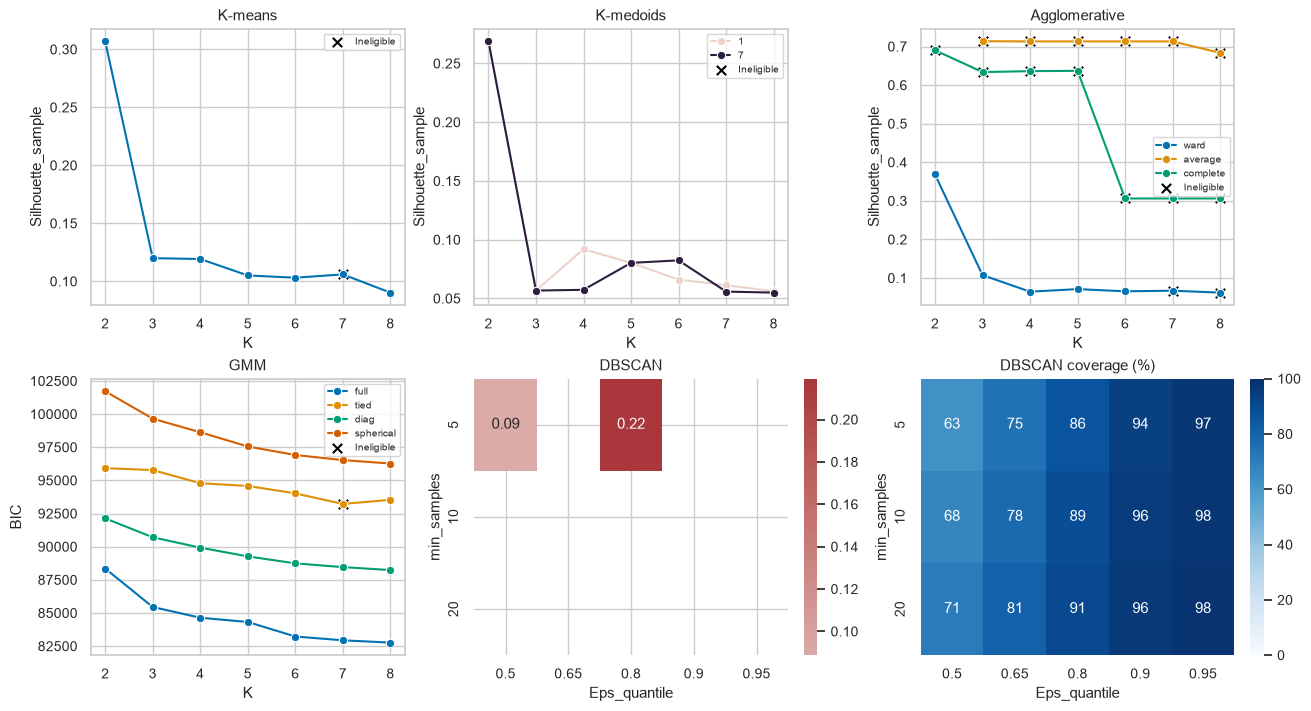

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
for ax, name in zip(axes.flat, model_classes):
    table = trials.loc[trials["Calibration"].eq("Standard") & trials["Model"].eq(name)].copy()
    if name == "DBSCAN":
        table["min_samples"] = table["Parameters"].map(lambda p: p["min_samples"])
        sns.heatmap(table.pivot(index="min_samples", columns="Eps_quantile", values="Silhouette_sample"),
                    annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
    else:
        metric = "BIC" if name == "GMM" else "Silhouette_sample"
        hue = None
        if name == "Agglomerative":
            table["Linkage"] = table["Parameters"].map(lambda p: p["linkage"])
            hue = "Linkage"
        elif name == "K-medoids":
            table["Seed"] = table["Parameters"].map(lambda p: p["random_state"])
            hue = "Seed"
        elif name == "GMM":
            hue = "Covariance"
        sns.lineplot(data=table, x="K", y=metric, hue=hue, marker="o", ax=ax)
        bad = table.loc[~table["Eligible"]]
        ax.scatter(bad["K"], bad[metric], marker="x", color="black", s=45, label="Ineligible")
        ax.legend(fontsize=7)
    ax.set_title(name)
db = trials.loc[trials["Calibration"].eq("Standard") & trials["Model"].eq("DBSCAN")].copy()
db["min_samples"] = db["Parameters"].map(lambda p: p["min_samples"])
sns.heatmap(db.pivot(index="min_samples", columns="Eps_quantile", values="Coverage_pct"),
            annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, ax=axes.flat[-1])
axes.flat[-1].set_title("DBSCAN coverage (%)")
fig.savefig(output_dir / "tuning_grid.png", dpi=160)
plt.show()


## PCA95, robust scaling and initialization checks

Apply PCA95 and RobustScaler to the **new transformed inputs**. Keep each standard transformed winner's parameters/count; DBSCAN recalculates its selected neighbour quantile. These are sensitivity checks, not a renewed grid search or a replacement for the recorded score winner. Seed checks cover the selected transformed K-means, K-medoids and GMM configurations.


In [11]:
pca95_count = int(np.searchsorted(pca_variance["Cumulative variance"], 0.95) + 1)
robust_values = RobustScaler().fit_transform(df_transformed)
robust_pca = PCA(n_components=np.linalg.matrix_rank(robust_values - robust_values.mean(axis=0)), svd_solver="full")
representations["PCA95"] = data_pca.iloc[:, :pca95_count].to_numpy()
representations["Robust"] = robust_pca.fit_transform(robust_values)
for calibration in ["PCA95", "Robust"]:
    values = representations[calibration]
    fit_distances[calibration] = squareform(pdist(values))
    for _, winner in transformed_selected.loc[transformed_selected["Eligible"]].iterrows():
        name = winner["Model"]
        parameters = winner["Parameters"].copy()
        if name == "DBSCAN":
            neighbours = NearestNeighbors(n_neighbors=parameters["min_samples"]).fit(values)
            distances = neighbours.kneighbors(values)[0][:, -1]
            parameters["eps"] = float(np.quantile(distances, winner["Eps_quantile"]))
        row = fit_model(name, model_classes[name](**parameters), calibration, "Calibration", winner["Eps_quantile"])
        reference, labels = assignments[winner["Run"]], assignments[row["Run"]]
        common = (reference >= 0) & (labels >= 0)
        row["ARI_vs_standard"] = adjusted_rand_score(reference[common], labels[common])
        row["Shared_assigned_pct"] = 100 * common.mean()
calibrations = pd.DataFrame(rows).query("Stage == 'Calibration'")
display(calibrations[["Model", "Calibration", "Fit_dimensions", "Clusters", "Silhouette_sample", "Min_size", "Coverage_pct", "ARI_vs_standard", "Eligible"]].round(4))


,Model,Calibration,Fit_dimensions,Clusters,Silhouette_sample,Min_size,Coverage_pct,ARI_vs_standard,Eligible
180,K-means,PCA95,9,2,0.3059,889,100.0,0.9953,True
181,K-medoids,PCA95,9,2,0.2690,1030,100.0,0.9851,True
182,Agglomerative,PCA95,9,2,0.1715,1582,100.0,0.0994,True
183,GMM,PCA95,9,8,0.0329,51,100.0,0.3418,True
184,K-means,Robust,11,2,0.3294,764,100.0,0.8312,True
185,K-medoids,Robust,11,2,0.2689,973,100.0,0.7962,True
186,Agglomerative,Robust,11,2,0.2891,809,100.0,0.4381,True
187,GMM,Robust,11,8,-0.0179,76,100.0,0.3242,True


In [12]:
seed_rows = []
for name in ["K-means", "K-medoids", "GMM"]:
    table = transformed_selected.loc[transformed_selected["Model"].eq(name) & transformed_selected["Eligible"]]
    if table.empty:
        continue
    winner = table.iloc[0]
    runs, eligible = [], []
    for seed in [1, 7, 21]:
        parameters = dict(winner["Parameters"], random_state=seed)
        row = fit_model(name, model_classes[name](**parameters), stage="Seed check")
        row["Seed"] = seed
        runs.append(assignments[row["Run"]])
        eligible.append(row["Eligible"])
    agreements = [adjusted_rand_score(a, b) for a, b in combinations(runs, 2)]
    seed_rows.append(dict(Model=name, Mean_ARI=np.mean(agreements), Minimum_ARI=np.min(agreements), All_eligible=all(eligible)))
seed_summary = pd.DataFrame(seed_rows)
seed_summary.round(4)


Out[12]: 
       Model  Mean_ARI  Minimum_ARI  All_eligible
0    K-means    1.0000       1.0000          True
1  K-medoids    1.0000       1.0000          True
2        GMM    0.4988       0.3979          True


## Exact silhouettes and common-space comparison

Compute exact silhouette for the displayed baselines, selections and calibrations as a check, without reselecting. Then score both sets of selected labels in **both reference geometries** on the same sampled dates. A better native score alone does not establish a better state model. Membership ARI compares each method's transformed selection with its independently tuned matched-date level selection, allowing different counts.


In [13]:
comparison = pd.DataFrame(rows).query("Stage == 'Baseline' or Stage == 'Calibration'").copy()
comparison = pd.concat([comparison, selected.loc[selected["Eligible"]].assign(Stage="Selected")], ignore_index=True)
comparison["Silhouette_full"] = np.nan
for i, row in comparison.iterrows():
    labels = assignments[row["Run"]]
    keep = labels >= 0
    reference = "Levels" if row["Calibration"] == "Levels" else "Standard"
    if 2 <= len(np.unique(labels[keep])) < keep.sum():
        comparison.loc[i, "Silhouette_full"] = silhouette_score(evaluation_distances[reference][np.ix_(keep, keep)], labels[keep], metric="precomputed")
selected["Silhouette_full"] = selected["Run"].map(comparison.set_index("Run")["Silhouette_full"])
selected["Seed_stability_ARI"] = np.nan
standard_mask = selected["Calibration"].eq("Standard")
selected.loc[standard_mask, "Seed_stability_ARI"] = selected.loc[standard_mask, "Model"].map(seed_summary.set_index("Model")["Mean_ARI"])
reference_rows = []
for _, row in selected.loc[selected["Eligible"]].iterrows():
    labels = assignments[row["Run"]][score_indices]
    keep = labels >= 0
    for reference in ["Standard", "Levels"]:
        value = silhouette_score(score_distances[reference][np.ix_(keep, keep)], labels[keep], metric="precomputed")
        reference_rows.append(dict(Model=row["Model"], Calibration=row["Calibration"], Reference=reference, Silhouette_sample=value))
reference_scores = pd.DataFrame(reference_rows)
common_scores = reference_scores.pivot(index=["Model", "Calibration"], columns="Reference", values="Silhouette_sample")
common_scores.columns = ["Silhouette in " + name + " space" for name in common_scores.columns]
agreement_rows = []
for name in model_classes:
    pair = selected.loc[selected["Model"].eq(name) & selected["Eligible"]].set_index("Calibration")
    if not {"Standard", "Levels"}.issubset(pair.index):
        continue
    a, b = assignments[pair.loc["Standard", "Run"]], assignments[pair.loc["Levels", "Run"]]
    keep = (a >= 0) & (b >= 0)
    agreement_rows.append(dict(Model=name, ARI=adjusted_rand_score(a[keep], b[keep]), Shared_assigned_pct=100*keep.mean()))
representation_agreement = pd.DataFrame(agreement_rows)
display(selected[summary_columns + ["Silhouette_full", "Seed_stability_ARI"]].round(4))
display(common_scores.round(4))
display(representation_agreement.round(4))


,Calibration,Model,Clusters,Silhouette_sample,Calinski_Harabasz,Davies_Bouldin,Min_size,Coverage_pct,Eligible,Silhouette_full,Seed_stability_ARI
0,Standard,K-means,2.0,0.3070,958.0783,1.6907,891.0,100.0000,True,0.3010,1.0000
1,Standard,K-medoids,2.0,0.2689,926.8588,1.7509,1025.0,100.0000,True,0.2709,1.0000
2,Standard,Agglomerative,2.0,0.3684,659.0280,1.5822,372.0,100.0000,True,0.3813,NaN
3,Standard,GMM,8.0,0.0012,199.4294,4.2378,90.0,100.0000,True,-0.0013,0.4988
4,Standard,DBSCAN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
5,Levels,K-means,2.0,0.2736,986.3110,1.7053,920.0,100.0000,True,0.2735,NaN
6,Levels,K-medoids,2.0,0.1982,738.5057,2.0011,1476.0,100.0000,True,0.1949,NaN
7,Levels,Agglomerative,2.0,0.2819,737.8876,1.5968,509.0,100.0000,True,0.3016,NaN
8,Levels,GMM,8.0,0.1527,517.9991,1.9328,120.0,100.0000,True,0.1531,NaN
9,Levels,DBSCAN,4.0,0.0579,100.9414,1.6317,38.0,82.1865,True,0.0419,NaN


Silhouette in Levels space  Silhouette in Standard space
Model         Calibration                                                          
Agglomerative Levels                           0.2819                        0.3241
              Standard                         0.3211                        0.3684
DBSCAN        Levels                           0.0579                        0.0726
GMM           Levels                           0.1527                       -0.0172
              Standard                         0.0303                        0.0012
K-means       Levels                           0.2736                        0.3002
              Standard                         0.2764                        0.3070
K-medoids     Levels                           0.1982                        0.0273
              Standard                         0.2406                        0.2689

,Model,ARI,Shared_assigned_pct
0,K-means,0.8795,100.0
1,K-medoids,0.0507,100.0
2,Agglomerative,0.5442,100.0
3,GMM,0.1904,100.0


## Financial profiles of all selected partitions

Use the original contemporaneous levels/descriptors for context, even though only four rate/spread inputs are now changes. Also save means of the new transformed features for every selected fit. S&P log returns remain the mandatory clustering input; daily simple returns are recovered with `expm1` for volatility/loss/CVaR. These are descriptive profiles, not formal tests or EP outputs.


In [14]:
def empirical_cvar(returns, alpha):
    losses = np.sort(-np.asarray(returns))[::-1]
    mass = len(losses) * (1 - alpha)
    whole = int(np.floor(mass))
    return (losses[:whole].sum() + (mass-whole)*losses[whole]) / mass

risk_rows, original_mean_rows, transformed_mean_rows = [], [], []
for _, winner in selected.loc[selected["Eligible"]].iterrows():
    labels = assignments[winner["Run"]]
    for cluster in np.unique(labels[labels >= 0]):
        values = df.loc[labels == cluster]
        returns = np.expm1(values["sp500_log_return"])
        risk_rows.append(dict(Model=winner["Model"], Calibration=winner["Calibration"], Cluster=cluster,
            Rows=len(values), Share_pct=100*len(values)/len(df), Mean_log_pct=100*values["sp500_log_return"].mean(),
            Mean_simple_pct=100*returns.mean(), Volatility_pct=100*returns.std(ddof=0), Loss_probability_pct=100*returns.lt(0).mean(),
            CVaR90_pct=100*empirical_cvar(returns,0.90), CVaR95_pct=100*empirical_cvar(returns,0.95)))
        original_mean_rows.append(dict(Model=winner["Model"], Calibration=winner["Calibration"], Cluster=cluster, **values.mean().to_dict()))
        transformed_mean_rows.append(dict(Model=winner["Model"], Calibration=winner["Calibration"], Cluster=cluster,
                                          **df_transformed.loc[labels == cluster].mean().to_dict()))
risk_profiles = pd.DataFrame(risk_rows)
original_profile_means = pd.DataFrame(original_mean_rows)
transformed_profile_means = pd.DataFrame(transformed_mean_rows)
display(risk_profiles.loc[risk_profiles["Calibration"].eq("Standard")].round(3))


,Model,Calibration,Cluster,Rows,Share_pct,Mean_log_pct,Mean_simple_pct,Volatility_pct,Loss_probability_pct,CVaR90_pct,CVaR95_pct
0,K-means,Standard,0,2713,75.277,0.155,0.157,0.668,41.430,1.006,1.271
1,K-means,Standard,1,891,24.723,-0.261,-0.245,1.753,57.688,3.242,4.082
2,K-medoids,Standard,0,1025,28.441,-0.285,-0.271,1.661,59.317,3.094,3.911
3,K-medoids,Standard,1,2579,71.559,0.186,0.188,0.646,39.938,0.900,1.133
4,Agglomerative,Standard,0,3232,89.678,0.130,0.133,0.777,42.915,1.269,1.616
5,Agglomerative,Standard,1,372,10.322,-0.624,-0.596,2.279,67.473,4.238,5.252
6,GMM,Standard,0,803,22.281,0.007,0.011,0.805,50.311,1.443,1.710
7,GMM,Standard,1,454,12.597,0.073,0.075,0.679,50.661,0.982,1.159
8,GMM,Standard,2,484,13.430,-0.100,-0.091,1.348,52.066,2.439,2.834
9,GMM,Standard,3,391,10.849,0.107,0.109,0.593,43.223,0.914,1.084


## Detailed transformed-data score winner

Labels use all informative coordinates. PC1/PC2 provide only a view. Keep local cluster IDs, show any DBSCAN noise separately, and exclude noise from profiles. Profile boxplots below compare both the **actual transformed inputs** and the **original-level economic context** under the same assignments.


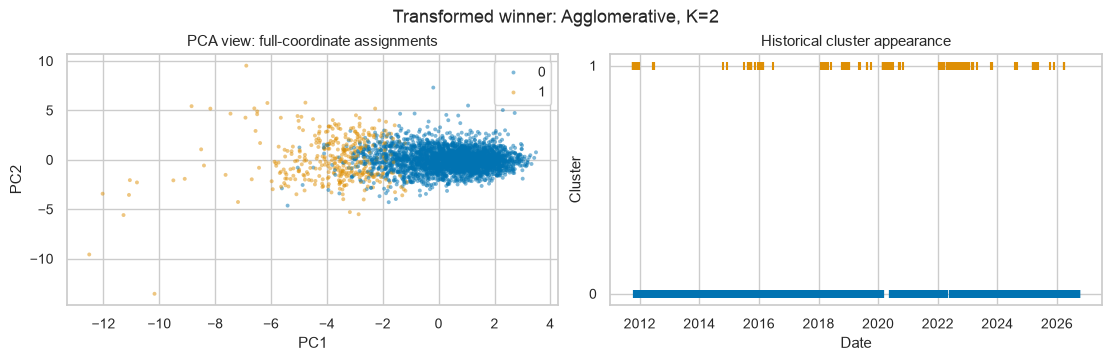

In [15]:
profile = df_transformed.assign(Cluster=score_winner_labels)
original_profile = df.assign(Cluster=score_winner_labels)
cluster_order = sorted(np.unique(score_winner_labels[score_winner_labels >= 0]))
palette = dict(zip(cluster_order, sns.color_palette("colorblind", len(cluster_order))))
palette[-1] = "grey"
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
sns.scatterplot(x=data_pca["PC1"], y=data_pca["PC2"], hue=score_winner_labels,
                palette=palette, s=8, linewidth=0, alpha=0.5, ax=axes[0])
axes[0].set(title="PCA view: full-coordinate assignments", xlabel="PC1", ylabel="PC2")
for cluster in sorted(np.unique(score_winner_labels)):
    dates = df.index[score_winner_labels == cluster]
    axes[1].scatter(dates, np.repeat(cluster, len(dates)), marker="|", s=40, color=palette[cluster])
axes[1].set(title="Historical cluster appearance", xlabel="Date", ylabel="Cluster", yticks=sorted(np.unique(score_winner_labels)))
fig.suptitle(f"Transformed winner: {score_winner['Model']}, K={int(score_winner['Clusters'])}")
fig.savefig(output_dir / "selected_model_views.png", dpi=160)
plt.show()


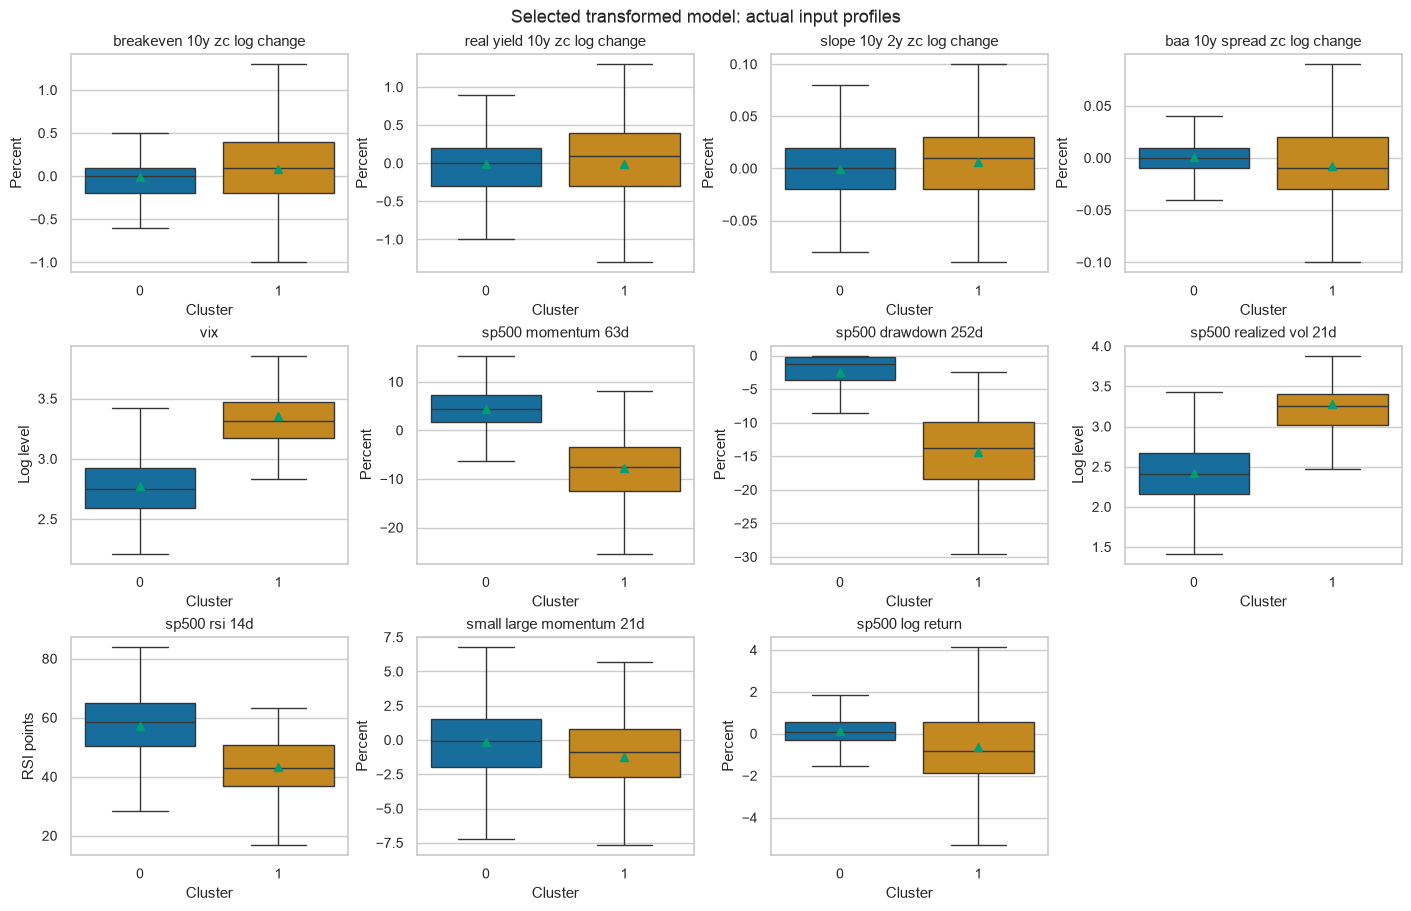

In [16]:
plot_profile = profile.loc[profile["Cluster"].ge(0)].copy()
percent_columns = [column for column in df_transformed.columns if column not in ["sp500_rsi_14d"] + vol_columns]
plot_profile[percent_columns] *= 100
fig, axes = plt.subplots(3, 4, figsize=(14, 9), layout="constrained")
for ax, variable in zip(axes.flat, df_transformed.columns):
    sns.boxplot(data=plot_profile, x="Cluster", y=variable, hue="Cluster", palette="colorblind",
                legend=False, showmeans=True, showfliers=False, ax=ax)
    ax.set(title=variable.replace("_", " "), xlabel="Cluster", ylabel="Percent" if variable in percent_columns else "Log level" if variable in vol_columns else "RSI points")
for ax in axes.flat[len(df_transformed.columns):]:ax.set_visible(False)
fig.suptitle("Selected transformed model: actual input profiles")
fig.savefig(output_dir / "selected_transformed_boxplots.png", dpi=160)
plt.show()


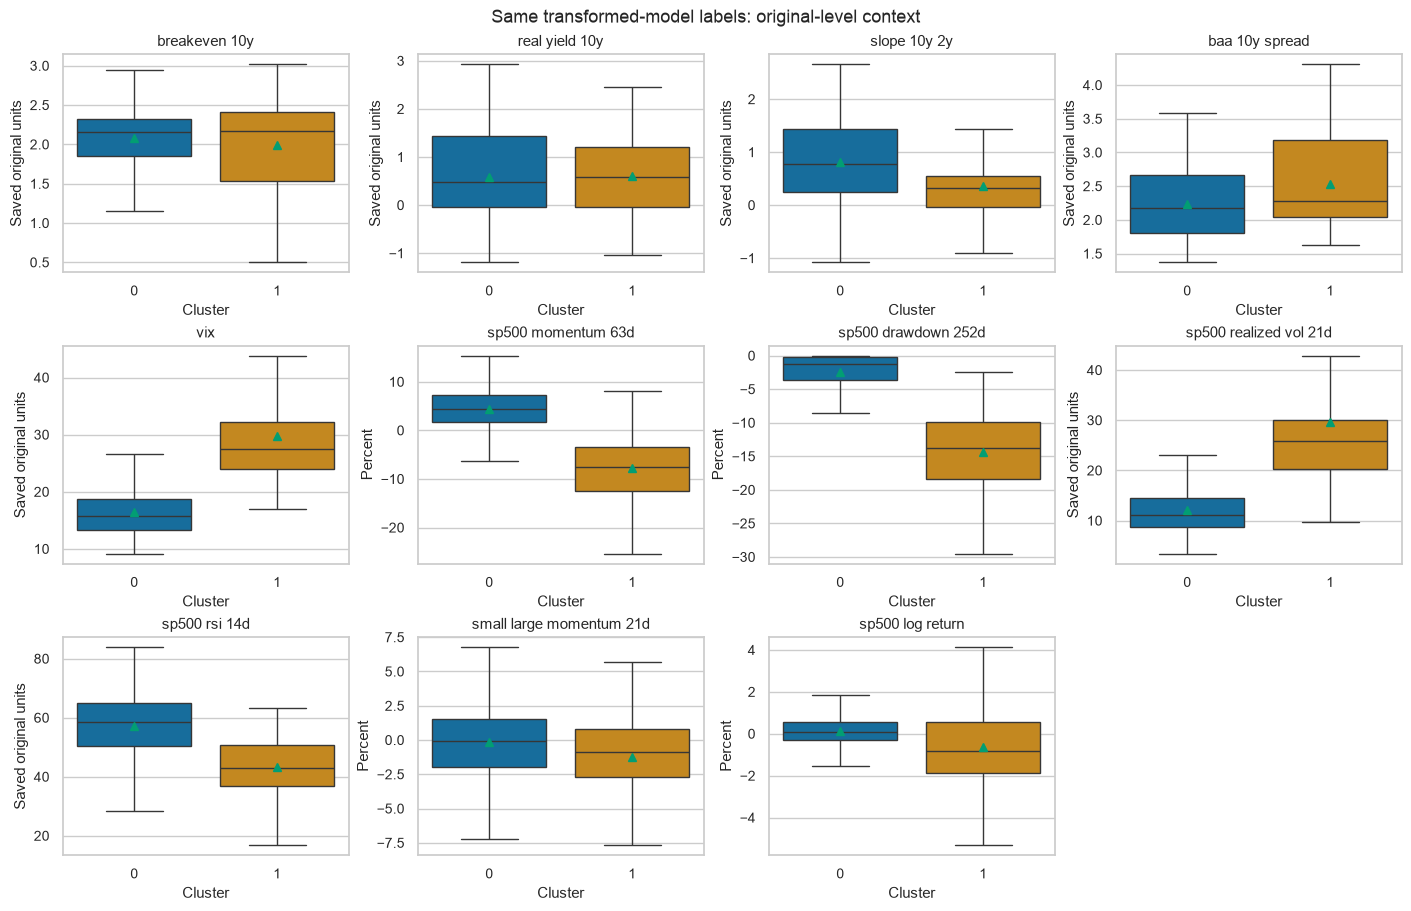

In [17]:
context_plot = original_profile.loc[original_profile["Cluster"].ge(0)].copy()
percent_columns = ["sp500_log_return", "sp500_momentum_63d", "sp500_drawdown_252d", "small_large_momentum_21d"]
context_plot[percent_columns] *= 100
fig, axes = plt.subplots(3, 4, figsize=(14, 9), layout="constrained")
for ax, variable in zip(axes.flat, df.columns):
    sns.boxplot(data=context_plot, x="Cluster", y=variable, hue="Cluster", palette="colorblind",
                legend=False, showmeans=True, showfliers=False, ax=ax)
    ax.set(title=variable.replace("_", " "), xlabel="Cluster", ylabel="Percent" if variable in percent_columns else "Saved original units")
for ax in axes.flat[len(df.columns):]:ax.set_visible(False)
fig.suptitle("Same transformed-model labels: original-level context")
fig.savefig(output_dir / "selected_original_context_boxplots.png", dpi=160)
plt.show()


Selected transformed fit:


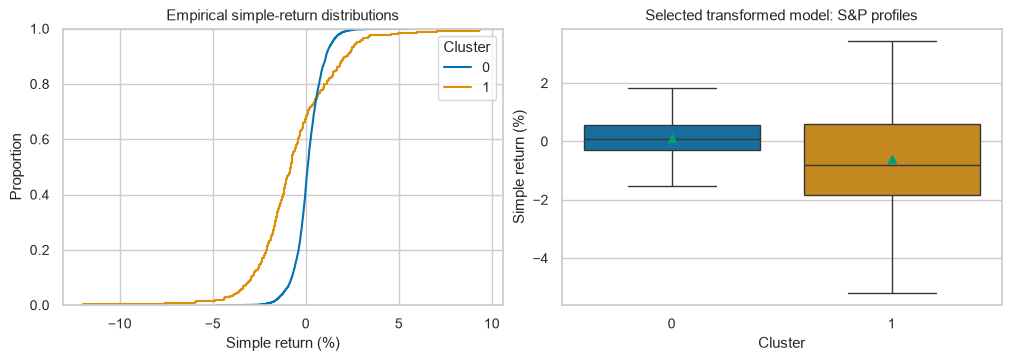

,Model,Calibration,Cluster,Rows,Share_pct,Mean_log_pct,Mean_simple_pct,Volatility_pct,Loss_probability_pct,CVaR90_pct,CVaR95_pct
4,Agglomerative,Standard,0,3232,89.678,0.130,0.133,0.777,42.915,1.269,1.616
5,Agglomerative,Standard,1,372,10.322,-0.624,-0.596,2.279,67.473,4.238,5.252
18,Agglomerative,Levels,0,3095,85.877,0.045,0.048,0.798,45.170,1.534,1.969
19,Agglomerative,Levels,1,509,14.123,0.095,0.115,2.024,47.151,3.556,4.612


In [18]:
equity_plot = original_profile.loc[original_profile["Cluster"].ge(0), ["Cluster"]].copy()
equity_plot["Simple return (%)"] = 100 * np.expm1(df.loc[equity_plot.index, "sp500_log_return"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
sns.ecdfplot(data=equity_plot, x="Simple return (%)", hue="Cluster", palette=palette, ax=axes[0])
sns.boxplot(data=equity_plot, x="Cluster", y="Simple return (%)", hue="Cluster", palette="colorblind",
            legend=False, showmeans=True, showfliers=False, ax=axes[1])
axes[0].set_title("Empirical simple-return distributions")
axes[1].set_title("Selected transformed model: S&P profiles")
fig.savefig(output_dir / "selected_equity_profiles.png", dpi=160)
plt.show()
print("Selected transformed fit:")
display(risk_profiles.loc[risk_profiles["Model"].eq(score_winner["Model"])].round(3))


## Save results and finish with the full comparison

“Standard” means the chapter-3.1 transformed specification; “Levels” means notebook 04's specification **refitted and fully retuned on the matched dates**. PCA95/Robust rows are checks of the transformed winners. Full-sample descriptive outputs do not establish stationarity, forecasting value or an EP improvement. Changing levels to changes also changes the economic question from conditions to shocks.


In [19]:
all_fits = pd.DataFrame(rows)
for name, table in {"all_fits": all_fits, "all_tuning_trials": trials, "selected_models": selected,
    "model_comparison": comparison, "initialization_stability": seed_summary,
    "reference_scores": reference_scores, "representation_agreement": representation_agreement,
    "equity_profiles": risk_profiles, "original_profile_means": original_profile_means,
    "transformed_profile_means": transformed_profile_means, "transformations": transformation_table}.items():
    table.to_csv(output_dir / f"{name}.csv", index=False)
for name, table in {"matched_original_inputs": df, "transformed_inputs": df_transformed,
                    "scaled_inputs": scaled_df, "persistence": persistence, "pca_variance": pca_variance}.items():
    table.to_csv(output_dir / f"{name}.csv")
pd.DataFrame(assignments, index=df.index).to_csv(output_dir / "all_assignments.csv", index_label="date")
profile[["Cluster"]].to_csv(output_dir / "score_winner_assignments.csv", index_label="date")
pd.Series(df.index[score_indices],name="date").to_csv(output_dir / "selection_score_dates.csv",index=False)
settings = dict(source_notebook="chapter3_1.ipynb", features=df.columns.tolist(), transformed_features=df_transformed.columns.tolist(),
    rows=len(df), original_04_rows=len(old_dates), excluded_dates=len(old_dates)-len(df),
    start=str(df.index.min().date()), end=str(df.index.max().date()), reference_maturities=rate_maturities.to_dict(),
    rate_transformation="log(exp(-tau*y/100)).diff()", volatility_transformation="natural log levels, unchanged from 04; no time differences",
    unchanged_from_04=[c for c in df.columns if c not in rate_columns],
    fixed_maturity_equivalence_error=float(equivalence_error), score_rows=1000, score_seed=123,
    k_values=list(k_values), minimum_cluster_rows=minimum_size, minimum_coverage_pct=80,
    trials_per_representation=85, score_winner_run=score_winner["Run"], score_winner_model=score_winner["Model"],
    score_winner_parameters=score_winner["Parameters"], fit_dimensions=int(score_winner["Fit_dimensions"]),
    matched_level_control="full independent grid on identical dates; original 04 log-level specification",
    interpretation="discount proxies, not actual zero-coupon bond returns; no stationarity proof; downstream EP results saved separately")
(output_dir/"settings.json").write_text(json.dumps(settings,indent=2))
print(f"{len(trials)} tuning trials on {len(df):,} shared dates. Transformed winner: {score_winner['Model']}, K={int(score_winner['Clusters'])}")
display(selected[summary_columns + ["Silhouette_full", "Seed_stability_ARI"]].round(4))
display(selected[["Calibration", "Model", "Parameters", "BIC"]])


170 tuning trials on 3,604 shared dates. Transformed winner: Agglomerative, K=2


,Calibration,Model,Clusters,Silhouette_sample,Calinski_Harabasz,Davies_Bouldin,Min_size,Coverage_pct,Eligible,Silhouette_full,Seed_stability_ARI
0,Standard,K-means,2.0,0.3070,958.0783,1.6907,891.0,100.0000,True,0.3010,1.0000
1,Standard,K-medoids,2.0,0.2689,926.8588,1.7509,1025.0,100.0000,True,0.2709,1.0000
2,Standard,Agglomerative,2.0,0.3684,659.0280,1.5822,372.0,100.0000,True,0.3813,NaN
3,Standard,GMM,8.0,0.0012,199.4294,4.2378,90.0,100.0000,True,-0.0013,0.4988
4,Standard,DBSCAN,NaN,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
5,Levels,K-means,2.0,0.2736,986.3110,1.7053,920.0,100.0000,True,0.2735,NaN
6,Levels,K-medoids,2.0,0.1982,738.5057,2.0011,1476.0,100.0000,True,0.1949,NaN
7,Levels,Agglomerative,2.0,0.2819,737.8876,1.5968,509.0,100.0000,True,0.3016,NaN
8,Levels,GMM,8.0,0.1527,517.9991,1.9328,120.0,100.0000,True,0.1531,NaN
9,Levels,DBSCAN,4.0,0.0579,100.9414,1.6317,38.0,82.1865,True,0.0419,NaN


,Calibration,Model,Parameters,BIC
0,Standard,K-means,"{'algorithm': 'lloyd', 'copy_x': True, 'init':...",NaN
1,Standard,K-medoids,"{'init': 'random', 'max_iter': 300, 'method': ...",NaN
2,Standard,Agglomerative,"{'compute_distances': False, 'compute_full_tre...",NaN
3,Standard,GMM,"{'covariance_type': 'full', 'init_params': 'km...",82767.682941
4,Standard,DBSCAN,NaN,NaN
5,Levels,K-means,"{'algorithm': 'lloyd', 'copy_x': True, 'init':...",NaN
6,Levels,K-medoids,"{'init': 'random', 'max_iter': 300, 'method': ...",NaN
7,Levels,Agglomerative,"{'compute_distances': False, 'compute_full_tre...",NaN
8,Levels,GMM,"{'covariance_type': 'full', 'init_params': 'km...",61087.636857
9,Levels,DBSCAN,"{'algorithm': 'auto', 'eps': 1.576126258038189...",NaN


## Reading the corrected rates-only run

**Only four inputs received new change transformations:** 10-year breakeven inflation, 10-year real yield, 10y–2y Treasury slope and the Baa–Treasury spread. All other inputs retain notebook 04's definitions: VIX and realized volatility stay log levels without differencing; momentum, drawdown, RSI, relative momentum and the S&P daily log return are unchanged. The seven unchanged model-input series match the level control exactly before scaling.

The rate/spread lag-one correlations fall from about 0.996–0.999 to between -0.045 and 0.134. VIX and technical-feature correlations are unchanged. This is a persistence diagnostic, not a stationarity test.

The score winner is now **Ward hierarchical clustering K=2**, with selection-sample silhouette **0.368** and full-sample silhouette **0.381**, and groups of **3,232 and 372 dates**. K-means selects K=2 (full silhouette **0.301**, groups **2,713 and 891**); K-medoids also selects two groups (0.271). GMM selects eight full-covariance components by BIC (full silhouette about -0.001); no DBSCAN candidate passes the population/coverage rules.

K-means has identical assignments across the tested seeds, PCA95 ARI **0.995**, and robust-scaling ARI **0.831**. Its ARI with the independently retuned matched-date level K-means fit is **0.879**. Hierarchical calibration checks are eligible, but their ARIs with the standard fit are lower: **0.099** for PCA95 and **0.438** for robust scaling. Thus the hierarchy wins the declared score comparison, while K-means is the more consistent of these two models under the tested representation changes.

In this corrected K-means fit, local cluster 0 is relatively calm (mean daily log return **+0.155%**) and cluster 1 is the lower-return/higher-risk profile (**-0.261%**). These IDs need not match notebook 04. Observed return differences remain descriptive because S&P returns entered clustering.

Both complete 85-candidate searches use **3,604 matched dates**, with shared-reference scores retained separately from native scores. Removing rate/spread persistence has not established a true regime count, formal stationarity, or improved EP results. Notebook 04 remains unchanged. The section below runs EP for this rates-only specification and an independently refitted matched-date level control.


## Upstream transformation reference

The discount-factor log-change construction is adapted from `chapter3_1.ipynb` in Anton Vorobets's pcrm-book examples. The original notice for the adapted upstream example is retained here:

```text
pcrm-book - Next generation investment analysis.
Copyright (C) 2025 Anton Vorobets.

This program is free software: you can redistribute it and/or modify
it under the terms of the GNU General Public License as published by
the Free Software Foundation, either version 3 of the License, or
(at your option) any later version.

This program is distributed in the hope that it will be useful,
but WITHOUT ANY WARRANTY; without even the implied warranty of
MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE. See the
GNU General Public License for more details.

You should have received a copy of the GNU General Public License
along with this program. If not, see <https://www.gnu.org/licenses/>.
```


## K-means K=2: EP and comparison with 04

Use each specification's **standard-scaled K-means K=2** fit, with 20 starts and seed 1. This is the requested EP application choice; Ward remains the silhouette winner above. Follow the same Vorobets/Fortitudo steps as notebook 04: cluster means as equality views, population variances as second-moment caps, an exponential-decay prior with half-life T/2, and Fully Flexible Resampling.

The **S&P return is excluded from all ten EP views**. Only four conditioning features differ between versions: discount-proxy log changes in 05 versus rate/spread levels in 04. VIX and realized volatility retain their log levels, and the technical descriptors retain their definitions.

Compare three cases: **05 rates-only**, **04 matched dates** (the fully retuned level control on the same 3,604 dates), and **04 original** (the saved 3,630-date results). Use the matched-date comparison to assess the representation change; the original comparison additionally contains a sample change. This does not isolate changes in clustering from changes in the EP view coordinates, since both follow the chosen representation.


In [20]:
import fortitudo.tech as ft
from scipy.optimize import linear_sum_assignment

ep_dir = output_dir / "ep"
ep_dir.mkdir(exist_ok=True)
ep_choice = selected.loc[selected["Model"].eq("K-means") & selected["Calibration"].eq("Standard")].iloc[0]
level_choice = selected.loc[selected["Model"].eq("K-means") & selected["Calibration"].eq("Levels")].iloc[0]
assert ep_choice["Clusters"] == level_choice["Clusters"] == 2

ep_inputs = {"05 rates-only": scaled_df.drop(columns="sp500_log_return"),
             "04 matched dates": level_scaled_df.drop(columns="sp500_log_return")}
ep_labels = {"05 rates-only": assignments[ep_choice["Run"]],
             "04 matched dates": assignments[level_choice["Run"]]}
anchor_labels = pd.read_csv("data/fixed_feature_clustering/ep_selected_assignments.csv",
                            index_col="date", parse_dates=["date"])["Cluster"]
anchor_names = {0: "Stress", 1: "Calmer"}
profile_names, matching_rows = {}, []
for version, labels in ep_labels.items():
    overlap = pd.crosstab(anchor_labels.loc[df.index], labels)
    reference, local = linear_sum_assignment(-overlap.to_numpy())
    profile_names[version] = {int(overlap.columns[j]): anchor_names[int(overlap.index[i])]
                              for i, j in zip(reference, local)}
    matching_rows.append({"Version": version,
        "Matched overlap (%)": 100 * overlap.to_numpy()[reference, local].sum() / len(df),
        "Cluster 0": profile_names[version][0], "Cluster 1": profile_names[version][1]})
profile_matching = pd.DataFrame(matching_rows)
profile_matching


Out[1]: 
            Version  Matched overlap (%) Cluster 0 Cluster 1
0     05 rates-only            97.114317    Calmer    Stress
1  04 matched dates            99.972253    Stress    Calmer


### Solve both ten-feature view systems

Each profile reweights all matched historical rows. For 05, the four rate/spread moments concern discount-proxy log changes; for the matched 04 control they concern levels. The other six conditioning features have the same transformations. Neither system specifies an equity-return mean, variance or CVaR.


In [21]:
ep_probabilities, ep_priors, ep_diagnostic_rows = {}, {}, []
for version, inputs in ep_inputs.items():
    values = inputs.to_numpy()
    labels = ep_labels[version]
    p_exp = ft.exp_decay_probs(inputs, half_life=len(inputs) / 2)
    A = np.vstack([np.ones(len(values)), values.T])
    G = values.T ** 2
    probabilities = []
    for state in [0, 1]:
        cluster = values[labels == state]
        mu = cluster.mean(axis=0)
        variance = cluster.var(axis=0)
        b = np.r_[1, mu][:, None]
        h = (variance + mu**2)[:, None]
        q = ft.entropy_pooling(p_exp, A, b, G, h)
        q = q / q.sum()
        probabilities.append(q)
        positive_q = q[q > 0]
        ep_diagnostic_rows.append({"Version": version, "Cluster": state,
            "Profile": profile_names[version][state],
            "Max mean error": np.abs(A @ q - b).max(),
            "Max bound violation": np.maximum(G @ q - h, 0).max(),
            "Entropy-effective scenarios": np.exp(-np.sum(positive_q * np.log(positive_q)))})
    ep_probabilities[version] = np.hstack(probabilities)
    ep_priors[version] = p_exp

ep_diagnostics = pd.DataFrame(ep_diagnostic_rows)
assert ep_diagnostics[["Max mean error", "Max bound violation"]].to_numpy().max() < 1e-5
assert all(np.isfinite(q).all() and (q >= 0).all() and np.allclose(q.sum(axis=0), 1)
           for q in ep_probabilities.values())
ep_diagnostics.set_index(["Version", "Profile"]).round(6)


Out[2]: 
                          Cluster  ...  Entropy-effective scenarios
Version          Profile           ...                             
05 rates-only    Calmer         0  ...                  2773.530701
                 Stress         1  ...                  1204.411153
04 matched dates Stress         0  ...                  1282.461309
                 Calmer         1  ...                  2881.858189

[4 rows x 4 columns]


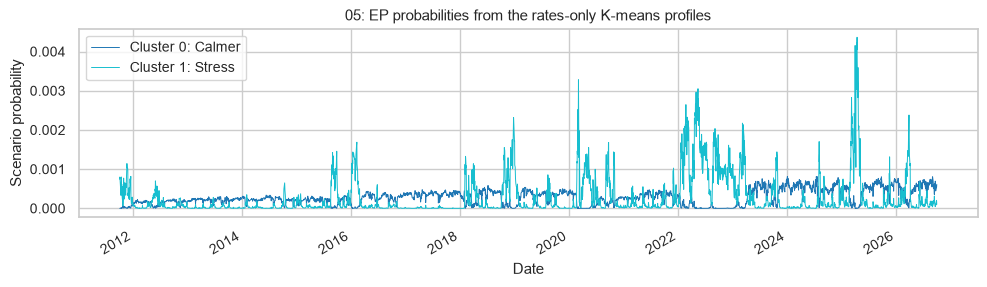

In [22]:
q05 = pd.DataFrame(ep_probabilities["05 rates-only"], index=df.index,
                  columns=[f"Cluster {state}: {profile_names['05 rates-only'][state]}" for state in [0, 1]])
ax = q05.plot(figsize=(10, 3), colormap="tab10", linewidth=0.7)
ax.set(title="05: EP probabilities from the rates-only K-means profiles", xlabel="Date", ylabel="Scenario probability")
ax.figure.tight_layout()
ax.figure.savefig(ep_dir / "ep_probabilities.png", dpi=160)
plt.show()


### State changes and 10,000 paths

Sample a historical row under the current state's EP weights and update the state to that row's K-means label, exactly as in 04. The transition matrices below are implied by those weights, not estimates from consecutive historical states.

Generate 10,000 paths of 21 observations per initial profile. Use seed 0 and simulate Stress then Calmer for both versions, matching 04's original order while retaining local fitted cluster IDs. Recover **simple returns** with `expm1(r)` for one day and `expm1(sum(r))` for 21 days.


In [23]:
transitions, transition_rows = {}, []
for version, q in ep_probabilities.items():
    labels = ep_labels[version]
    transition = np.array([[q[labels == next_state, state].sum() for next_state in [0, 1]]
                           for state in [0, 1]])
    transitions[version] = transition
    for state in [0, 1]:
        for next_state in [0, 1]:
            transition_rows.append({"Version": version, "From cluster": state,
                "From profile": profile_names[version][state], "To cluster": next_state,
                "To profile": profile_names[version][next_state], "Probability": transition[state, next_state]})
transition_table = pd.DataFrame(transition_rows)
transition_table.pivot(index=["Version", "From profile"], columns="To profile", values="Probability").round(4)


Out[4]: 
To profile                     Calmer  Stress
Version          From profile                
04 matched dates Calmer        0.9559  0.0441
                 Stress        0.1461  0.8539
05 rates-only    Calmer        0.9463  0.0537
                 Stress        0.1535  0.8465


In [24]:
asset_returns = df[["sp500_log_return"]]
resampler = ft.FullyFlexibleResampling(asset_returns)
S, H = 10000, 21
log_paths, daily_samples, monthly_samples = {}, {}, {}
for version, q in ep_probabilities.items():
    np.random.seed(0)
    for profile_name in ["Stress", "Calmer"]:
        state = next(state for state, name in profile_names[version].items() if name == profile_name)
        paths = resampler.simulate(S, H, q, ep_labels[version], initial_state=state)
        key = (version, profile_name)
        log_paths[key] = paths[:, 0, :]
        daily_samples[key] = np.expm1(paths[:, 0, 0])
        monthly_samples[key] = np.expm1(paths[:, 0, :].sum(axis=1))

original_daily = pd.read_csv("data/fixed_feature_clustering/ep/one_day_simple_returns.csv")
original_monthly = pd.read_csv("data/fixed_feature_clustering/ep/21_day_simple_returns.csv")
for state, profile_name in anchor_names.items():
    daily_samples[("04 original", profile_name)] = original_daily[f"Initial cluster {state}"].to_numpy()
    monthly_samples[("04 original", profile_name)] = original_monthly[f"Initial cluster {state}"].to_numpy()

simulated_daily_returns = pd.DataFrame(daily_samples)
simulated_returns = pd.DataFrame(monthly_samples)
for table in [simulated_daily_returns, simulated_returns]:
    table.columns = pd.MultiIndex.from_tuples(table.columns, names=["Version", "Initial profile"])


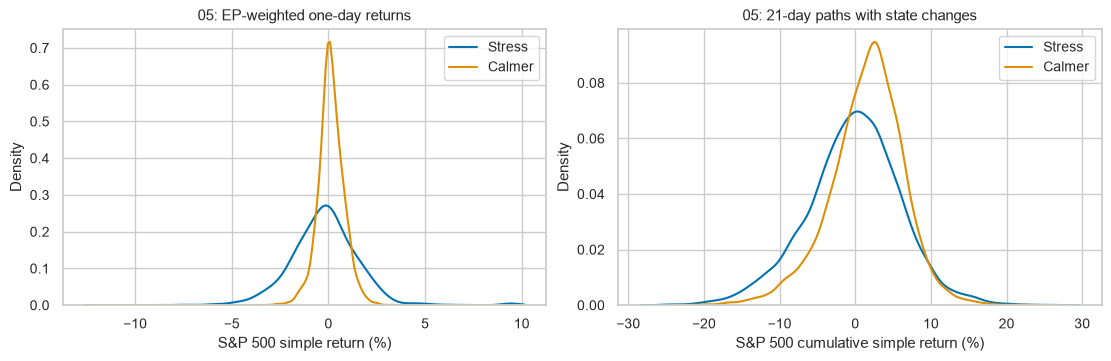

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
for profile_name in ["Stress", "Calmer"]:
    state = next(state for state, name in profile_names["05 rates-only"].items() if name == profile_name)
    sns.kdeplot(x=100 * np.expm1(asset_returns.iloc[:, 0]), weights=ep_probabilities["05 rates-only"][:, state],
                label=profile_name, ax=axes[0])
    sns.kdeplot(x=100 * simulated_returns[("05 rates-only", profile_name)], label=profile_name, ax=axes[1])
axes[0].set(title="05: EP-weighted one-day returns", xlabel="S&P 500 simple return (%)")
axes[1].set(title="05: 21-day paths with state changes", xlabel="S&P 500 cumulative simple return (%)")
for ax in axes: ax.legend()
fig.savefig(ep_dir / "sp500_return_distributions.png", dpi=160)
plt.show()


### Return and CVaR comparison

All table entries are percentages and use simple returns. The one-day statistics use the first simulated step, while the one-day density above uses historical posterior weights directly. CVaR uses **`fortitudo.tech.portfolio_cvar` with `demean=False`**; positive values represent losses. At 21 days, the profile describes the initial state and subsequent state changes are allowed.

Profile names are aligned to the original 04 groups by maximum date overlap, not by re-ranking the simulated return means. The original 04 results are loaded rather than overwritten or rerun.


In [26]:
return_samples = pd.concat({"1 day": simulated_daily_returns, "21 days": simulated_returns}, axis=1, names=["Horizon"])
ep_return_summary = return_samples.describe(percentiles=[0.05, 0.5, 0.95]).loc[
    ["mean", "std", "5%", "50%", "95%"]
].T * 100
ep_return_summary["Loss probability (%)"] = 100 * return_samples.lt(0).mean()
exposures = np.eye(return_samples.shape[1])
for alpha in [0.90, 0.95]:
    cvars = ft.portfolio_cvar(exposures, return_samples, alpha=alpha, demean=False)
    ep_return_summary[f"CVaR {alpha:.0%} (%)"] = 100 * cvars[0]
ep_return_summary = ep_return_summary.rename(columns={"mean": "Mean (%)", "std": "Std (%)",
    "5%": "5th percentile (%)", "50%": "Median (%)", "95%": "95th percentile (%)"})
ep_return_summary = ep_return_summary.reorder_levels(["Version", "Horizon", "Initial profile"]).sort_index()
display(ep_return_summary.round(2))
matched_difference = ep_return_summary.loc["05 rates-only"] - ep_return_summary.loc["04 matched dates"]
print("05 minus matched-date 04: differences in percentage points")
matched_difference.round(2)


05 minus matched-date 04: differences in percentage points
Out[7]: 
                         Mean (%)  Std (%)  ...  CVaR 90% (%)  CVaR 95% (%)
Horizon Initial profile                     ...                            
1 day   Calmer               0.02     0.01  ...         -0.03         -0.03
        Stress              -0.05     0.10  ...          0.26          0.33
21 days Calmer              -0.20     0.33  ...          0.87          1.00
        Stress              -0.51     0.40  ...          1.34          1.66

[4 rows x 8 columns]


Mean (%)  ...  CVaR 95% (%)
Version          Horizon Initial profile            ...              
04 matched dates 1 day   Calmer               0.12  ...          1.42
                         Stress              -0.12  ...          3.69
                 21 days Calmer               1.69  ...          9.35
                         Stress               0.28  ...         12.51
04 original      1 day   Calmer               0.13  ...          1.38
                         Stress              -0.15  ...          3.81
                 21 days Calmer               1.60  ...          9.26
                         Stress               0.18  ...         13.20
05 rates-only    1 day   Calmer               0.14  ...          1.40
                         Stress              -0.17  ...          4.02
                 21 days Calmer               1.49  ...         10.35
                         Stress              -0.23  ...         14.16

[12 rows x 8 columns]

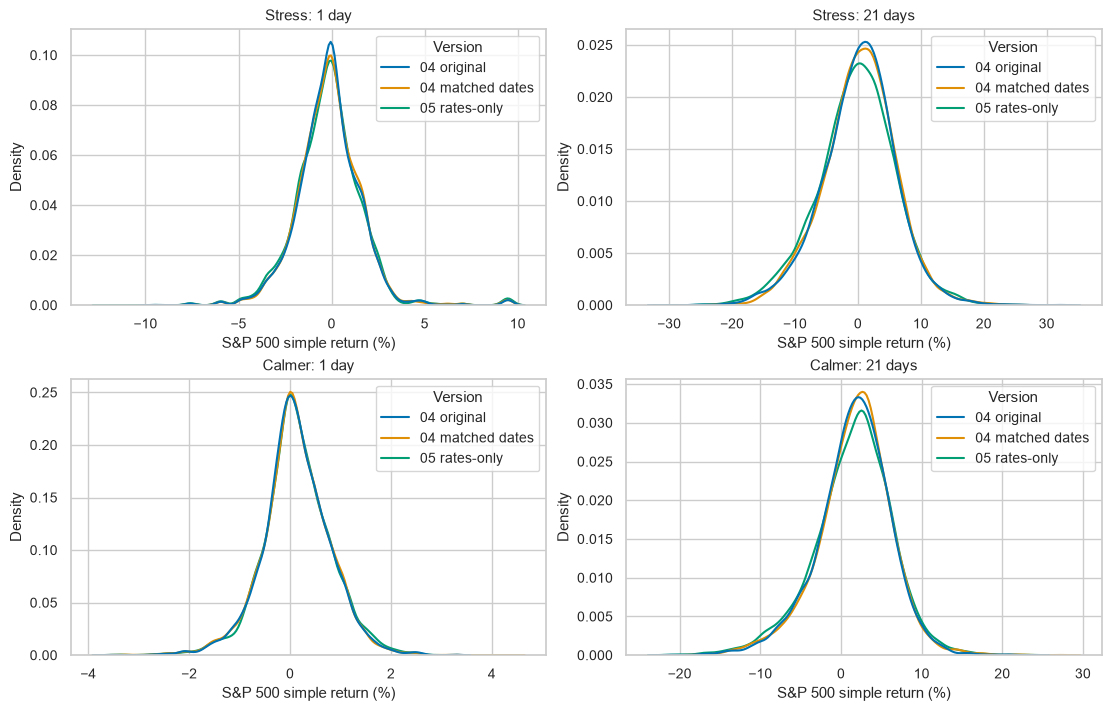

In [27]:
plot_frames = []
for horizon, table in [("1 day", simulated_daily_returns), ("21 days", simulated_returns)]:
    for version, profile_name in table.columns:
        plot_frames.append(pd.DataFrame({"Return (%)": 100 * table[(version, profile_name)],
                                        "Version": version, "Profile": profile_name, "Horizon": horizon}))
comparison_plot = pd.concat(plot_frames, ignore_index=True)
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for i, profile_name in enumerate(["Stress", "Calmer"]):
    for j, horizon in enumerate(["1 day", "21 days"]):
        data = comparison_plot.loc[comparison_plot["Profile"].eq(profile_name) & comparison_plot["Horizon"].eq(horizon)]
        sns.kdeplot(data=data, x="Return (%)", hue="Version", palette="colorblind",
                    hue_order=["04 original", "04 matched dates", "05 rates-only"], ax=axes[i, j])
        axes[i, j].set(title=f"{profile_name}: {horizon}", xlabel="S&P 500 simple return (%)")
fig.savefig(ep_dir / "comparison_with_04.png", dpi=160)
plt.show()


### Interpreting the comparison

Use **05 versus 04 matched dates** for the cleanest available representation comparison: the historical rows, half-life rule, asset returns, simulation size, seed and horizon are shared. Each version uses its own fitted scaler, K-means labels and feature-moment targets. Hence the difference reflects the combined clustering/view specification, not the isolated effect of changing only EP constraints.

The original 04 reference additionally differs by 26 historical observations and its original fitted profiles. Different CVaR values describe different conditional scenario distributions; lower CVaR is not, by itself, evidence of better calibration or predictive accuracy. The constraints concern features, not the S&P return, and variance views are caps rather than exact matches.

In this run, the matched-date 21-day CVaR95 increases from **12.51% to 14.16%** for the stressed start and from **9.35% to 10.35%** for the calmer start. The corresponding CVaR90 changes are **10.48% to 11.82%** and **7.24% to 8.11%**. The 05 stressed-start mean is approximately **-0.17% for one day and -0.23% for 21 days**; the calmer-start means are **+0.14% and +1.49%**. The profiles remain different, but these numbers establish a change in modeled risk rather than a ranking of model quality.


In [28]:
for version, folder in [("05 rates-only", ep_dir), ("04 matched dates", ep_dir / "matched_04")]:
    folder.mkdir(exist_ok=True)
    labels = ep_labels[version]
    inputs = ep_inputs[version]
    pd.DataFrame(ep_probabilities[version], index=df.index, columns=["Cluster 0", "Cluster 1"]).to_csv(folder / "posterior_probabilities.csv", index_label="date")
    pd.DataFrame(ep_priors[version], index=df.index, columns=["Prior probability"]).to_csv(folder / "prior_probabilities.csv", index_label="date")
    pd.Series(labels, index=df.index, name="Cluster").to_csv(folder / "assignments.csv", index_label="date")
    inputs.to_csv(folder / "view_inputs.csv", index_label="date")
    inputs.groupby(labels).mean().to_csv(folder / "view_means.csv", index_label="Cluster")
    inputs.groupby(labels).var(ddof=0).to_csv(folder / "view_variances.csv", index_label="Cluster")
    for horizon, table in [("one_day", simulated_daily_returns), ("21_day", simulated_returns)]:
        table[version].to_csv(folder / f"{horizon}_simple_returns.csv", index=False)
    np.savez_compressed(folder / "log_return_paths.npz", **{name: log_paths[(version, name)] for name in ["Stress", "Calmer"]})
    ep_return_summary.loc[version].to_csv(folder / "return_summary.csv")
ep_return_summary.to_csv(ep_dir / "comparison_return_summary.csv")
matched_difference.to_csv(ep_dir / "matched_difference.csv")
ep_diagnostics.to_csv(ep_dir / "ep_diagnostics.csv", index=False)
transition_table.to_csv(ep_dir / "transition_probabilities.csv", index=False)
profile_matching.to_csv(ep_dir / "profile_matching.csv", index=False)
ep_settings = {"model": "K-means", "clusters": 2, "n_init": 20, "model_seed": 1,
    "rate_only_run": ep_choice["Run"], "matched_level_run": level_choice["Run"],
    "rows": len(df), "original_04_rows": len(anchor_labels), "half_life": len(df)/2,
    "view_features": {version: inputs.columns.tolist() for version, inputs in ep_inputs.items()},
    "profile_names": profile_names, "paths_per_profile": S, "horizon": H, "simulation_seed": 0,
    "simulation_profile_order": ["Stress", "Calmer"], "mean_views": "equalities",
    "variance_views": "second-moment upper bounds", "return_units": "simple returns",
    "cvar": "fortitudo.tech.portfolio_cvar; demean=False", "profile_alignment": "maximum date overlap to original 04",
    "comparison": "original 04 saved outputs plus a separately refitted matched-date level control"}
(ep_dir / "settings.json").write_text(json.dumps(ep_settings, indent=2))
print("EP complete for 05 and matched-date 04; no S&P return views.")
display(ep_return_summary[["Mean (%)", "Std (%)", "Loss probability (%)", "CVaR 90% (%)", "CVaR 95% (%)"]].round(2))


EP complete for 05 and matched-date 04; no S&P return views.


Mean (%)  ...  CVaR 95% (%)
Version          Horizon Initial profile            ...              
04 matched dates 1 day   Calmer               0.12  ...          1.42
                         Stress              -0.12  ...          3.69
                 21 days Calmer               1.69  ...          9.35
                         Stress               0.28  ...         12.51
04 original      1 day   Calmer               0.13  ...          1.38
                         Stress              -0.15  ...          3.81
                 21 days Calmer               1.60  ...          9.26
                         Stress               0.18  ...         13.20
05 rates-only    1 day   Calmer               0.14  ...          1.40
                         Stress              -0.17  ...          4.02
                 21 days Calmer               1.49  ...         10.35
                         Stress              -0.23  ...         14.16

[12 rows x 5 columns]